# Customer Loyalty Scorer — G2 consulting reviews

**Run in VS Code on your Mac:** put this notebook in your `STRAT 560` folder. In that same folder, create `review_exports` and add the four CSVs listed below. Select a Python 3 kernel and run all cells from top to bottom. No live G2 request is made, so there is no HTTP 403 during scoring.

This startup has no customer reviews yet. The comparison covers **four competitors**: DXC Technology Services, IBM Consulting, Accenture, and Fujitsu Consulting. The data were transcribed from saved G2 review-page PDFs, and the CSV `include` and `relevance_note` columns document the client-service screen. Use the linked original G2 profile and the source PDF, reviewer, date, and title to trace each record. The saved pages did not expose individual review permalinks.

**Files required in `STRAT 560/review_exports`:** `DXC_Technology_Services_G2_reviews.csv`, `IBM_Consulting_G2_reviews.csv`, `Accenture_G2_reviews.csv`, and `Fujitsu_Consulting_G2_reviews.csv`.


In [ ]:
# Uncomment and run only if these packages are missing in your VS Code kernel.
# %pip install pandas matplotlib


## 1. Load and audit the four CSV files

Only rows marked `TRUE` in `include` are scored. We retain the exact G2 half-star rating. A raw **0/5 is mapped to a scoring rating of 1/5** (a detractor), while the original 0 remains visible in the CSV. No other rating is rounded.

The PDFs contain some reviews about employment, software products, or unclear reviewer relationships. The `include` flags document these judgments and may be edited before rerunning. We take the **50 most recent eligible reviews** per company where possible; otherwise we report the actual sample. The published G2 total includes reviews outside the consulting scope.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('review_exports')  # relative to the notebook's working folder
TARGET = 50
COMPANIES = {
    'DXC Technology Services': ('DXC_Technology_Services_G2_reviews.csv',
                                'https://www.g2.com/products/dxc-technology-services/reviews', 6),
    'IBM Consulting': ('IBM_Consulting_G2_reviews.csv',
                       'https://www.g2.com/products/ibm-consulting/reviews', 65),
    'Accenture': ('Accenture_G2_reviews.csv',
                  'https://www.g2.com/products/accenture/reviews', 108),
    'Fujitsu Consulting': ('Fujitsu_Consulting_G2_reviews.csv',
                           'https://www.g2.com/products/fujitsu-consulting/reviews', 10),
}
required = {'company','source','profile_url','source_pdf','reviewer','date','title',
            'rating','project_or_task','like_text','dislike_text','include','relevance_note'}

frames = []
for company, (filename, profile, published_total) in COMPANIES.items():
    filepath = DATA_DIR / filename
    if not filepath.exists():
        raise FileNotFoundError(f'Missing {filepath}. Put all four CSVs in review_exports beside this notebook.')
    part = pd.read_csv(filepath, keep_default_na=False)
    missing = required - set(part.columns)
    if missing:
        raise ValueError(f'{filename}: missing columns {sorted(missing)}')
    if not part.company.eq(company).all() or not part.source.eq('G2').all():
        raise ValueError(f'{filename}: unexpected company or source')
    if not part.profile_url.eq(profile).all():
        raise ValueError(f'{filename}: unexpected G2 profile URL')
    flags = part['include'].astype(str).str.upper()
    if not flags.isin(['TRUE','FALSE']).all():
        raise ValueError(f'{filename}: include must contain only TRUE or FALSE')
    part['include'] = flags.eq('TRUE')
    part['rating'] = pd.to_numeric(part.rating, errors='raise')
    part['date'] = pd.to_datetime(part.date, errors='raise')
    if part[['reviewer','date','title']].duplicated().any():
        raise ValueError(f'{filename}: possible duplicate reviewer/date/title')
    if (((part.rating < 0) | (part.rating > 5)) & part['include']).any():
        raise ValueError(f'{filename}: an included review has a rating outside 0–5')
    # Keep half stars exactly; only map raw zero to one for scoring.
    part['scoring_rating'] = part['rating'].clip(lower=1)
    part['published_total'] = published_total  # total displayed in the saved G2 PDF
    frames.append(part)

reviews = pd.concat(frames, ignore_index=True)
audit = (reviews.groupby('company', sort=False)
         .agg(source_cards=('rating','size'), eligible=('include','sum'),
              published_total=('published_total','first'),
              first_review_date=('date','min'), last_review_date=('date','max'))
         .reset_index())
audit['excluded'] = audit.source_cards - audit.eligible
display(audit)
print('Total eligible:', int(reviews['include'].sum()))


,company,source_cards,eligible,published_total,first_review_date,last_review_date,excluded
0,DXC Technology Services,6,3,6,2018-10-23,2023-10-26,3
1,IBM Consulting,65,45,65,2012-09-19,2026-07-26,20
2,Accenture,100,58,108,2013-03-12,2026-09-24,42
3,Fujitsu Consulting,10,7,10,2017-01-12,2023-10-05,3


Total eligible: 113


## 2. Calculate the two NPS definitions

Each eligible review counts once, including passives in the denominator.

| Rating used for scoring | Main rule | Alternative rule |
|---|---|---|
| 4.5–5.0 | Promoter | Promoter |
| 4.0 | Passive | Promoter |
| 3.5 | Passive | Passive |
| 1.0–3.0 (including a raw 0 mapped to 1) | Detractor | Detractor |

NPS = percentage of promoters minus percentage of detractors, rounded to a whole number. The alternative moves **only 4.0-star reviews**; `change_points` shows its difference from the main rule. Both scenarios use the same reviewed sample.


In [2]:
def nps_counts(ratings, four_is_promoter=False):
    n = len(ratings)
    if n == 0:
        return dict(n=0, promoters=0, passives=0, detractors=0,
                    promoter_pct=None, passive_pct=None, detractor_pct=None, nps=None)
    promoter_threshold = 4.0 if four_is_promoter else 4.5
    promoters = int((ratings >= promoter_threshold).sum())
    detractors = int((ratings <= 3.0).sum())
    passives = n - promoters - detractors  # 3.5, plus 4.0 under the main rule
    return dict(n=n, promoters=promoters, passives=passives, detractors=detractors,
                promoter_pct=100 * promoters / n, passive_pct=100 * passives / n,
                detractor_pct=100 * detractors / n,
                nps=round(100 * (promoters - detractors) / n))

selected = []
rows = []
for company, (filename, profile, published_total) in COMPANIES.items():
    eligible = reviews.loc[reviews.company.eq(company) & reviews['include']]
    sample = eligible.sort_values('date', ascending=False, kind='stable').head(TARGET).copy()
    selected.append(sample)
    main = nps_counts(sample.scoring_rating)
    alternative = nps_counts(sample.scoring_rating, four_is_promoter=True)
    rows.append(dict(company=company, source='G2', profile_url=profile,
                     published_total=published_total, source_cards=len(reviews.loc[reviews.company.eq(company)]),
                     eligible=len(eligible), scored_n=main['n'],
                     promoters_4_5_to_5=main['promoters'], passives_3_5_to_4=main['passives'],
                     detractors_1_to_3=main['detractors'],
                     promoter_pct=main['promoter_pct'], passive_pct=main['passive_pct'],
                     detractor_pct=main['detractor_pct'], nps_main=main['nps'],
                     alt_promoters_4_to_5=alternative['promoters'],
                     alt_promoter_pct=alternative['promoter_pct'],
                     nps_4_plus=alternative['nps'],
                     change_points=alternative['nps']-main['nps'] if main['n'] else None,
                     earliest_scored=sample.date.min().date() if main['n'] else None,
                     latest_scored=sample.date.max().date() if main['n'] else None))
scored = pd.concat(selected, ignore_index=True)
summary = pd.DataFrame(rows).sort_values('nps_main', ascending=False)
display(summary)


,company,source,profile_url,published_total,source_cards,eligible,scored_n,promoters_4_5_to_5,passives_3_5_to_4,detractors_1_to_3,promoter_pct,passive_pct,detractor_pct,nps_main,alt_promoters_4_to_5,alt_promoter_pct,nps_4_plus,change_points,earliest_scored,latest_scored
3,Fujitsu Consulting,G2,https://www.g2.com/products/fujitsu-consulting...,10,10,7,7,4,3,0,57.142857,42.857143,0.000000,57,7,100.000000,100,43,2021-07-19,2023-10-05
1,IBM Consulting,G2,https://www.g2.com/products/ibm-consulting/rev...,65,65,45,45,22,16,7,48.888889,35.555556,15.555556,33,31,68.888889,53,20,2012-09-19,2026-07-26
2,Accenture,G2,https://www.g2.com/products/accenture/reviews,108,100,58,50,24,18,8,48.000000,36.000000,16.000000,32,40,80.000000,64,32,2015-09-15,2026-09-24
0,DXC Technology Services,G2,https://www.g2.com/products/dxc-technology-ser...,6,6,3,3,1,1,1,33.333333,33.333333,33.333333,0,1,33.333333,0,0,2019-09-11,2023-10-26


## 3. NPS, consulting sample size, and the potential wedge

The paired bars show both scoring rules. The sample-size chart shows **reviews actually scored** for each company. Both scatterplots also use `scored_n` on the x-axis, so they compare the same consulting-related review samples used in NPS. A scored review count is neither a customer count nor market share. Treat any high-volume, lower-loyalty pattern as a lead for further investigation.


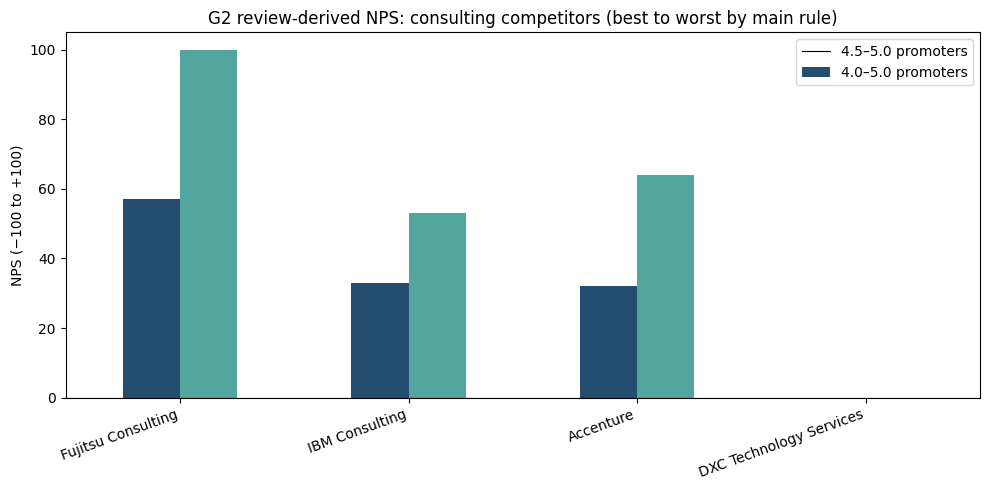

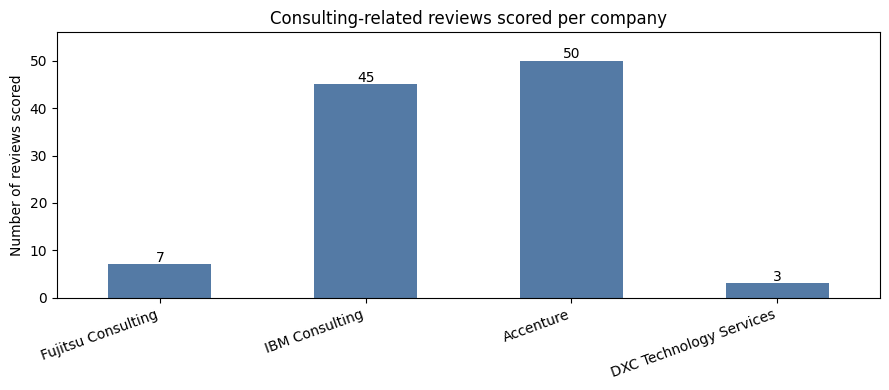

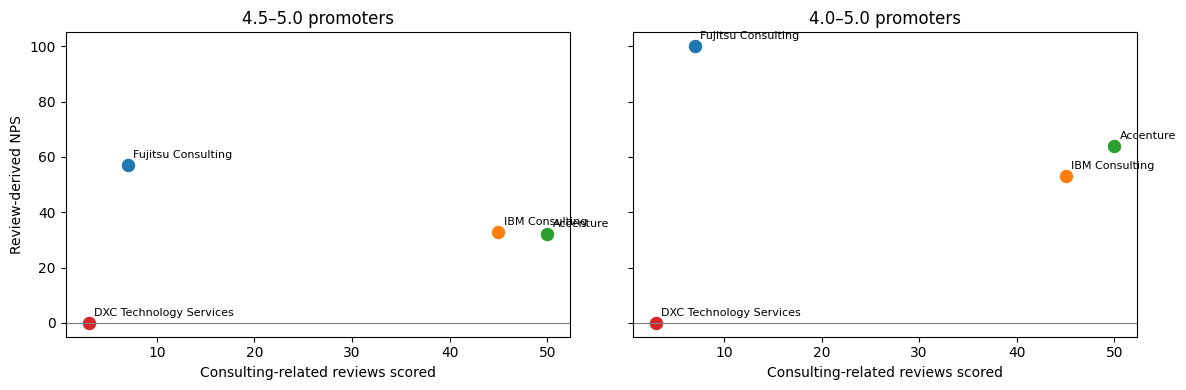

In [3]:
ax = summary.set_index('company')[['nps_main','nps_4_plus']].plot(
    kind='bar', figsize=(10,5), color=['#234E70','#53A69D'])
ax.set_title('G2 review-derived NPS: consulting competitors (best to worst by main rule)')
ax.set_ylabel('NPS (−100 to +100)')
ax.set_xlabel('')
ax.axhline(0, color='black', lw=.8)
ax.legend(['4.5–5.0 promoters','4.0–5.0 promoters'])
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

ax = summary.set_index('company')['scored_n'].plot.bar(
    figsize=(9,4), color='#547AA5')
ax.set_title('Consulting-related reviews scored per company')
ax.set_ylabel('Number of reviews scored')
ax.set_xlabel('')
ax.set_ylim(0, max(55, summary.scored_n.max() * 1.12))
for position, count in enumerate(summary.scored_n):
    ax.text(position, count + 0.6, str(count), ha='center')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax, column, label in zip(axes, ['nps_main','nps_4_plus'],
                             ['4.5–5.0 promoters','4.0–5.0 promoters']):
    for row in summary.itertuples():
        ax.scatter(row.scored_n, getattr(row,column), s=75)
        ax.annotate(row.company, (row.scored_n, getattr(row,column)),
                    xytext=(4,5), textcoords='offset points', fontsize=8)
    ax.set_title(label)
    ax.set_xlabel('Consulting-related reviews scored')
    ax.axhline(0, color='gray', lw=.8)
axes[0].set_ylabel('Review-derived NPS')
plt.tight_layout()
plt.show()


## 4. Check real example reviews and source references

The table chooses one included promoter, passive, and detractor **per company** under the main rule. `NOT FOUND` means the sampled reviews have none in that bucket. Excerpts are short verbatim passages from the saved G2 PDFs. Cite the PDF, reviewer, date, title, and profile URL in the report; the prints did not expose individual review permalinks. Inspect examples against their PDFs before submitting.


In [4]:
def short_excerpt(row, limit=22):
    words = (row['like_text'] or row['dislike_text'] or row['project_or_task']).split()
    return ' '.join(words[:limit]) if words else 'NOT FOUND'

examples = []
for company in COMPANIES:
    group = scored.loc[scored.company.eq(company)]
    for bucket, subset in [('Promoter (4.5–5)',group.loc[group.scoring_rating.ge(4.5)]),
                           ('Passive (3.5–4)',group.loc[group.scoring_rating.between(3.5,4.0)]),
                           ('Detractor (1–3)',group.loc[group.scoring_rating.le(3.0)])]:
        if subset.empty:
            examples.append(dict(company=company,bucket=bucket,rating='NOT FOUND',
                                 excerpt='NOT FOUND',source='NOT FOUND'))
        else:
            row = subset.iloc[0]
            examples.append(dict(company=company,bucket=bucket,original_rating=row.rating,
                                 scoring_rating=row.scoring_rating,excerpt=short_excerpt(row),
                                 reviewer=row.reviewer,date=row.date.date(),title=row.title,
                                 source=row.source_pdf,profile_url=row.profile_url))
display(pd.DataFrame(examples).fillna('NOT FOUND'))


,company,bucket,original_rating,scoring_rating,excerpt,reviewer,date,title,source,profile_url,rating
0,DXC Technology Services,Promoter (4.5–5),4.5,4.5,"Prompt responses, easy to go team and good man...",Verified User in Oil & Energy,2023-10-26,DXC Review,"DXC Technology Services Reviews 2026: Details,...",https://www.g2.com/products/dxc-technology-ser...,NOT FOUND
1,DXC Technology Services,Passive (3.5–4),3.5,3.5,The level of depth and breadth they bring to t...,Verified User in Environmental Services,2023-08-05,DXC technology review,"DXC Technology Services Reviews 2026: Details,...",https://www.g2.com/products/dxc-technology-ser...,NOT FOUND
2,DXC Technology Services,Detractor (1–3),3.0,3.0,"Helpful staff, good relationships, easy to con...",Verified User in Hospital & Health Care,2019-09-11,"Clunky software, helpful staff","DXC Technology Services Reviews 2026: Details,...",https://www.g2.com/products/dxc-technology-ser...,NOT FOUND
3,IBM Consulting,Promoter (4.5–5),5.0,5.0,Customization according to the client needs,Arnab S.,2026-07-26,Highly Customizable to Client Needs,IBM 1.pdf,https://www.g2.com/products/ibm-consulting/rev...,NOT FOUND
4,IBM Consulting,Passive (3.5–4),4.0,4.0,Knowledge of products and staying up to date w...,Naveed M.,2023-07-28,IBM Consulting Review,IBM 1.pdf,https://www.g2.com/products/ibm-consulting/rev...,NOT FOUND
5,IBM Consulting,Detractor (1–3),3.0,3.0,"Technical Knowledge, solutions, accessibility ...",Verified User in Medical Devices,2020-08-30,"Great experience, product could be costly.",IBM 4.pdf,https://www.g2.com/products/ibm-consulting/rev...,NOT FOUND
6,Accenture,Promoter (4.5–5),5.0,5.0,I like their structured approach to project de...,sangeeth s.,2026-09-24,Structured Project Delivery with Strong Cross-...,Acc 1.pdf,https://www.g2.com/products/accenture/reviews,NOT FOUND
7,Accenture,Passive (3.5–4),4.0,4.0,What I like best about Accenture is their abil...,Verified User in Consumer Goods,2026-04-21,"Strategic Thinking Backed by Scalable, Well-Go...",Acc 1.pdf,https://www.g2.com/products/accenture/reviews,NOT FOUND
8,Accenture,Detractor (1–3),3.0,3.0,They are experts in all matters relating to HR...,Karishma S.,2023-09-11,Great experience with highly experienced consu...,Acc 1.pdf,https://www.g2.com/products/accenture/reviews,NOT FOUND
9,Fujitsu Consulting,Promoter (4.5–5),5.0,5.0,They spend time in understanding your need ver...,Verified User in Information Technology and Se...,2022-12-07,"Fujitsu Consulting - flexible, scalable and re...",Fujitsu.pdf,https://www.g2.com/products/fujitsu-consulting...,NOT FOUND


## 5. Interpretation & Limitations

- **Method:** all four profiles use G2, but G2 reviews may be incentivized, self-selected, old, or about another service. The scope filter excludes reviews that do not clearly represent a customer of consulting, implementation, or managed services; review the `relevance_note` column. Use the original half-star ratings directly: 4.5–5 promoters, 3.5–4 passives, and 1–3 detractors. A raw 0 is treated as 1 for scoring. The alternative moves only 4.0 into promoters.
The results for Fujitsu and DXC Technology Services are limited -- especially in consulting. The NPS evaluation is therefore limited but also shows how wide open the industry is overall. These two companies are in the top 5 companies in terms of market share, yet they do not have a stronghold on the market with tons of promoters of their service to customers in the industry overall. 
- **Selection:** 50 most recent eligible reviews where possible; actual smaller count otherwise. Show the `source_cards`, `eligible`, `scored_n`, and `published_total` separately. The saved PDF pages may contain collapsed previews, and G2's sort order is not guaranteed to be chronological; we sort the captured eligible records by their dates. Review-derived NPS is a **proxy**, not survey NPS. People disproportionately post when delighted or upset, so the score can overstate polarization.

To share from VS Code, upload the notebook and the four CSVs together to a location the grader can open without signing in, or use a view-only notebook link that also makes its input files available. The notebook does not reproduce G2 reviews by contacting G2 at runtime.
